Para google colab montamos el drive de google y nos desplazamos a nuestra carpeta

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/Programacion/Python/Bots/SmartOVI

Estiramos la lista de archivos en el dataset

In [1]:
import os
archivos = os.listdir('dataset/')

import cv2
import numpy as np

Recorremos la lista de archivos y guardamos los datos en el dataframe

In [2]:

fechas = []
horas = []
cantidades = []

directorio = './dataset/'

for archivo in archivos:
    #contador de larvas
    cLarvas = 0
    
    imagen = cv2.imread(directorio + archivo)
    grises = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

    #se procede a realizar la umbralización con parámetros estáticos
    _,th = cv2.threshold(grises, 85, 255, cv2.THRESH_BINARY_INV)

    #se itera con operaciónes morfológicas sobre el resultado para eliminar el ruido
    kernel = np.ones((5,5),np.uint8)
    opening = cv2.morphologyEx(th, cv2.MORPH_OPEN,kernel)

    #se utiliza el algortimo de detección por contornos para detección de objetos
    cnts,_ = cv2.findContours(opening,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

    #ciclo para recorrer los contornos y dibujar rectangulos
    for contorno in cnts:
        (x,y,w,h) = cv2.boundingRect(contorno)
        if w>11 and h>11:                                       #parametros estáticos para no dibujar contornos pequeños (suciedad)
            cv2.rectangle(imagen,(x,y),(x+w,y+h),(255,0,0),2)
            cLarvas=cLarvas+1
    
    cantidades.append(cLarvas)
    fechas.append(archivo[0:4]+'-'+archivo[4:6]+'-'+archivo[6:8])
    horas.append(archivo[8:10]+':'+archivo[10:12])



Creamos el Dataframe donde almacenaremos los datos

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "cantidad":cantidades,
    "fecha":fechas,
    "hora": horas
})

display(df)

,cantidad,fecha,hora
0,6,2022-10-24,20:16
1,6,2022-10-24,20:20
2,3,2022-10-24,20:34
3,4,2022-10-24,20:36
4,4,2022-10-24,20:38
...,...,...,...
365,7,2022-10-25,09:48
366,5,2022-10-25,09:50
367,6,2022-10-25,09:52
368,4,2022-10-25,09:54


Presentamos los datos obtenidos

In [ ]:
import matplotlib.pyplot as plt

x = np.linspace(1,370,370)
y = cantidades

_,ax = plt.subplots()


ax.plot(x,y,'.')

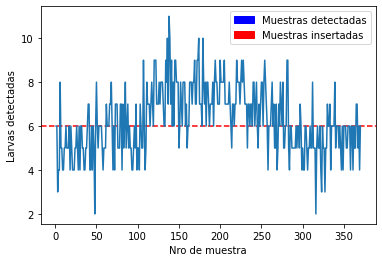

In [10]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

x = np.linspace(1,370,370)
y = cantidades

_,ax = plt.subplots()

ax.axhline(6, ls='--', color='r')

m_rojo = mpatches.Patch(color='red', label='Muestras insertadas')
m_blue = mpatches.Patch(color='blue', label='Muestras detectadas')
ax.legend(handles = [m_blue,m_rojo])

ax.set_ylabel("Larvas detectadas")
ax.set_xlabel("Nro de muestra")

ax.plot(x,y)


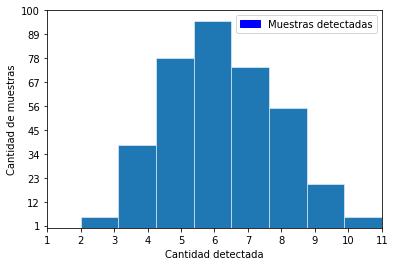

In [26]:
import matplotlib.pyplot as plt 
import numpy as np

_,ax = plt.subplots()

ax.hist(cantidades, bins=8, linewidth=0.5, edgecolor = "white")

m_blue = mpatches.Patch(color='blue', label='Muestras detectadas')
ax.legend(handles = [m_blue])

ax.set(xlim=(1,11), xticks = np.arange(1,12),ylim=(0,100),yticks=np.linspace(1,100,10))

ax.set_ylabel("Cantidad de muestras")
ax.set_xlabel("Cantidad detectada")

plt.show()